<a href="https://colab.research.google.com/github/aashiqafathima823-sketch/lstmmodel/blob/main/Spamsms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
from google.colab import files
import pandas as pd

# 1. Trigger the file upload dialog
print("Select your dataset file (CSV/TSV):")
uploaded = files.upload()

# 2. Get the uploaded filename automatically
file_name = list(uploaded.keys())[0]
print(f"Uploaded successfully: {file_name}")

# 3. Load the uploaded file into a DataFrame
try:
  df = pd.read_csv(file_name, encoding="latin-1")
except Exception:
  df = pd.read_csv(file_name, sep="\t", header=None)

# Display first few rows to verify
df.head()

Select your dataset file (CSV/TSV):


Saving spam_sms.csv to spam_sms (1).csv
Uploaded successfully: spam_sms (1).csv


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
import re
import pandas as pd

# 1. Select relevant columns and rename them
df = df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'message'})

# 2. Handle missing values
print(f"Missing values before cleanup:\n{df.isnull().sum()}")
df.dropna(subset=['label', 'message'], inplace=True)
df.drop_duplicates(inplace=True)

# 3. Filter to a manageable subset of ~2,000 labelled messages (stratified)
total_subset = min(2000, len(df))
df = (
    df.groupby('label', group_keys=False)
    .apply(
        lambda x: x.sample(
            int(total_subset * len(x) / len(df)), random_state=42
        )
    )
    .reset_index(drop=True)
)

# 4. Encode labels: ham -> 0, spam -> 1
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})


# 5. Preprocess and clean the SMS text
def preprocess_text(text):
  text = str(text).lower()  # Lowercase
  text = re.sub(r'http\S+|www\S+', '', text)  # Remove links/URLs
  text = re.sub(
      r'[^a-z\s]', '', text
  )  # Keep only lowercase letters and spaces
  text = re.sub(r'\s+', ' ', text).strip()  # Remove extra whitespaces
  return text


df['clean_message'] = df['message'].apply(preprocess_text)

# Verify the cleaned data
print(f"\nFinal dataset count: {len(df)}")
print(f"Class distribution:\n{df['label'].value_counts()}")
df[['message', 'clean_message', 'label_num']].head()

Missing values before cleanup:
label      0
message    0
dtype: int64

Final dataset count: 1999
Class distribution:
label
ham     1747
spam     252
Name: count, dtype: int64


/tmp/ipykernel_1391/3235894321.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,message,clean_message,label_num
0,"Come to me, slave. Your doing it again ... Goi...",come to me slave your doing it again going int...,0
1,U meet other fren dun wan meet me ah... Muz b ...,u meet other fren dun wan meet me ah muz b a g...,0
2,"G says you never answer your texts, confirm/deny",g says you never answer your texts confirmdeny,0
3,"K so am I, how much for an 8th? Fifty?",k so am i how much for an th fifty,0
4,HMM yeah if your not too grooved out! And im l...,hmm yeah if your not too grooved out and im lo...,0


In [ ]:
# Task 2: Tokenize and convert text to padded sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

# 1. Extract inputs and targets from the preprocessed DataFrame
X = df['clean_message'].values
y = df['label_num'].values

# 2. 80-20 stratified train/test split to preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Tokenizer configuration
VOCAB_SIZE = 5000
MAX_LEN = 50
OOV_TOKEN = '<OOV>'

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(X_train)

# 4. Convert text messages into padded numerical sequences
X_train_padded = pad_sequences(
    tokenizer.texts_to_sequences(X_train),
    maxlen=MAX_LEN,
    padding='post',
    truncating='post',
)
X_test_padded = pad_sequences(
    tokenizer.texts_to_sequences(X_test),
    maxlen=MAX_LEN,
    padding='post',
    truncating='post',
)

# Verification
print(f'Training samples: {X_train_padded.shape[0]}')
print(f'Testing samples:  {X_test_padded.shape[0]}')
print(f'Sequence length:   {X_train_padded.shape[1]}')
print(f'Sample padded sequence:\n{X_train_padded[0]}')

Training samples: 1599
Testing samples:  400
Sequence length:   50
Sample padded sequence:
[225   3 371   8 415  63  19   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]


In [ ]:
# =======================================================
# Task 3: Sequential Model (LSTM) Implementation
# Justification:
# LSTMs are preferred over simple RNNs because their gating
# mechanisms (forget, input, and output gates) avoid the
# vanishing gradient problem and effectively preserve long-term
# sequence context across message tokens.
# =======================================================
import tensorflow as tf
from tensorflow.keras.layers import LSTM, Dense, Dropout, Embedding
from tensorflow.keras.models import Sequential

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=64),
    Dropout(0.2),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid'),
])

model.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics=['accuracy'],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# =======================================================
# Task 4: Train and Evaluate Model
# =======================================================
from sklearn.metrics import classification_report

# Train the LSTM model
history = model.fit(
    X_train_padded,
    y_train,
    epochs=6,
    batch_size=32,
    validation_data=(X_test_padded, y_test),
    verbose=1,
)

# Predict probabilities on the test set
y_pred_probs = model.predict(X_test_padded)
y_pred = (y_pred_probs >= 0.5).astype(int)

# Print classification metrics
print("\n" + "=" * 55)
print("EVALUATION METRICS (Accuracy, Precision, Recall, F1-Score)")
print("=" * 55)
print(
    classification_report(y_test, y_pred, target_names=["Ham (0)", "Spam (1)"])
)

Epoch 1/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.8618 - loss: 0.4238 - val_accuracy: 0.8750 - val_loss: 0.3819
Epoch 2/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8737 - loss: 0.3852 - val_accuracy: 0.8750 - val_loss: 0.3650
Epoch 3/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9487 - loss: 0.1726 - val_accuracy: 0.9850 - val_loss: 0.0864
Epoch 4/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9619 - loss: 0.1486 - val_accuracy: 0.9600 - val_loss: 0.1947
Epoch 5/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9750 - loss: 0.1319 - val_accuracy: 0.9750 - val_loss: 0.1196
Epoch 6/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9875 - loss: 0.0691 - val_accuracy: 0.9750 - val_loss: 0.1179
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

EVALUATION METRICS (Accuracy, Precision, Recall, F1-Score)
              precision    recall  f1-score   support

     Ham (0)       0.98      0.99      0.99       350
    Spam (1)       0.93      0.86  

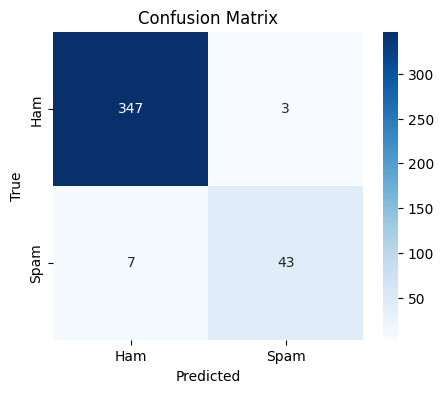

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step

Unseen SMS Predictions:
[SPAM] (Confidence: 0.9742) -> URGENT! You have won a 1000 cash prize. Call 0800123456 to claim now!
[HAM] (Confidence: 0.0113) -> Hey, are we still meeting for lunch at 1 PM today?
[SPAM] (Confidence: 0.9742) -> Free entry in 2 a weekly competition to win FA Cup final tickets! Text WIN to 87121
[HAM] (Confidence: 0.0113) -> Don't forget to submit the assignment before 5 PM.


In [ ]:
# =======================================================
# Task 5: Confusion Matrix & Unseen Message Predictions
# =======================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam'],
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


# 2. Test Unseen Messages
def predict_sms(messages):
  # Uses the clean function defined in your Task 1 cell
  clean = [preprocess_text(m) for m in messages]
  seqs = tokenizer.texts_to_sequences(clean)
  padded = pad_sequences(seqs, maxlen=MAX_LEN, padding='post')
  scores = model.predict(padded)

  print('\nUnseen SMS Predictions:')
  for msg, score in zip(messages, scores):
    label = 'SPAM' if score[0] >= 0.5 else 'HAM'
    print(f'[{label}] (Confidence: {score[0]:.4f}) -> {msg}')


unseen_tests = [
    'URGENT! You have won a 1000 cash prize. Call 0800123456 to claim now!',
    'Hey, are we still meeting for lunch at 1 PM today?',
    (
        'Free entry in 2 a weekly competition to win FA Cup final tickets! Text'
        ' WIN to 87121'
    ),
    "Don't forget to submit the assignment before 5 PM.",
]

predict_sms(unseen_tests)

In [ ]:
# Put any custom message inside this list
my_message = [
    "Congratulations! You won a free gift card. Reply CLAIM to get it now."
]

predict_sms(my_message)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step

Unseen SMS Predictions:
[SPAM] (Confidence: 0.9742) -> Congratulations! You won a free gift card. Reply CLAIM to get it now.
